# WHU data efficiency, initialization and training budget

## Summary

The study examines how labelled training-set size, encoder initialization and a bounded change in training budget interact on the WHU Aerial building-footprint task. The main learning curves use nested sets of 25, 100 and 500 images for three predeclared uniform-random selections (seeds 17, 29 and 43). All eighteen main runs share the same 4,000-update recipe and provider validation role.

ImageNet improves the best mean per-image validation intersection over union (IoU) in all nine main paired comparisons. Every n=25 endpoint is below its selected maximum, whereas every n=500 late IoU trend remains positive. Increasing data improves building overlap and reduces false building predictions on empty images in every selection and initialization.

A separate sensitivity analysis trains six fresh n=500 models for 8,000 updates while preserving every other condition. Random's mean IoU over the final five evaluations improves in all three continuations relative to the matching window ending at update 4,000; ImageNet improves in two and declines in one. ImageNet nevertheless retains a positive paired endpoint advantage for every selection.

These are validation results from three training-image selections with fixed remaining seeds. Their sample standard deviations describe image-selection variation; they are not confidence intervals, independent test results or geographic-generalization estimates.

## 1. Question and evaluation contract

WHU supplies native 512 × 512 RGB tiles and rasterized **building-footprint** labels. Raw label 0 denotes building and label 1 background; there is no invalid-pixel code. The primary metric is the equally weighted mean per-image building IoU at probability threshold 0.5. IoU is predicted/reference overlap divided by their union.

All 299 empty validation masks remain in the primary mean. An empty reference and empty prediction receive IoU and Dice one; any predicted building pixel makes both zero. Complementary diagnostics therefore report IoU, Dice and pixel average precision (AP) on the 737 positive-reference images and predicted building area on empty-reference images.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
RESULTS = pd.read_csv(ROOT / "reports/whu_learning_curve_results.csv")
EFFECTS = pd.read_csv(ROOT / "reports/whu_learning_curve_effects.csv")
GAINS = pd.read_csv(ROOT / "reports/whu_learning_curve_gains.csv")
SUMMARY = pd.read_csv(ROOT / "reports/whu_learning_curve_summary.csv")
OVERLAPS = pd.read_csv(ROOT / "reports/whu_learning_curve_overlaps.csv")
N100_EFFECTS = pd.read_csv(ROOT / "reports/whu_training_pilot_effects.csv")
CROSS_DATASET = pd.read_csv(ROOT / "reports/whu_rid_initialization_effects.csv")
EXAMPLES = pd.read_csv(ROOT / "reports/whu_training_pilot_examples.csv")
SPLITS = json.loads((ROOT / "data/metadata/whu/splits.json").read_text())
BUDGET_RESULTS = pd.read_csv(ROOT / "reports/whu_training_budget_results.csv")
BUDGET_PAIRED = pd.read_csv(ROOT / "reports/whu_training_budget_paired.csv")
BUDGET_SUMMARY = pd.read_csv(ROOT / "reports/whu_training_budget_summary.csv")
BUDGET_COMPARISON = pd.read_csv(ROOT / "reports/whu_rid_training_budget_comparison.csv")


## 2. Fixed method and nested subsets

Every model starts freshly: Random initializes the full network from the fixed model seed, while ImageNet loads only the original verified torchvision encoder weights; both decoders use the same fresh initialization. Training otherwise remains unchanged: ImageNet normalization, joint D4 image/target transformations, ordinary BatchNorm updates, equal-weight binary cross-entropy and soft-Dice loss, AdamW with weight decay 1e-4, batch size 4, learning rate 1e-3 through update 2,000 and 1e-4 through update 4,000. Validation occurs every 100 updates and selects the highest primary IoU.

Nested subsets are constructed around each fixed n=100 selection. For each seed, n=25 is sampled without replacement from its unchanged n=100 set; n=500 adds 400 images sampled from the remaining provider training pool. Derived seeds are `subset_seed × 1000 + 25` and `subset_seed × 1000 + 500`. Deterministically ordered source lists, isolated NumPy generators and no labels, masks, imagery or model results define the selections.

In [2]:
subset_rows = []
for repetition, record in SPLITS["learning_curve_subsets"]["repetitions"].items():
    subset_rows.append({
        "Repetition": int(repetition), "Subset seed": record["subset_seed"],
        "n=25 seed": record["derived_seeds"]["n25_from_n100"],
        "n=500 extension seed": record["derived_seeds"]["n500_extension"],
    })
pd.DataFrame(subset_rows)

,Repetition,Subset seed,n=25 seed,n=500 extension seed
0,1,17,17025,17500
1,2,29,29025,29500
2,3,43,43025,43500


In [3]:
OVERLAPS.rename(columns={
    "training_size": "Training images", "first_repetition": "First repetition",
    "first_seed": "First seed",
    "second_repetition": "Second repetition",
    "second_seed": "Second seed", "shared_ids": "Shared IDs",
})

,Training images,First repetition,First seed,Second repetition,Second seed,Shared IDs
0,25,1,17,2,29,0
1,100,1,17,2,29,5
2,500,1,17,2,29,49
3,25,1,17,3,43,0
4,100,1,17,3,43,2
5,500,1,17,3,43,44
6,25,2,29,3,43,0
7,100,2,29,3,43,2
8,500,2,29,3,43,61


The pairwise overlaps at n=25/100/500 are 0/5/49 IDs for seeds 17–29, 0/2/44 for 17–43 and 0/2/61 for 29–43. Each nested family satisfies 25 ⊂ 100 ⊂ 500 and remains entirely inside the provider training role. The 1,036-image validation role is unchanged, and the provider test role is absent from training, checkpoint selection and qualitative analysis.

## 3. Initialization effects at 100 images

The three n=100 selections test whether the ImageNet advantage persists when the training-image sample changes. Architecture, optimization and validation data are held fixed within each comparison.

,dataset,subset_seed,random_best_iou,imagenet_best_iou,imagenet_minus_random_best_iou,imagenet_minus_random_endpoint_iou
0,WHU,17,0.7116,0.8099,0.0983,0.0912
1,WHU,29,0.7334,0.8078,0.0744,0.0691
2,WHU,43,0.7045,0.7795,0.0750,0.1150


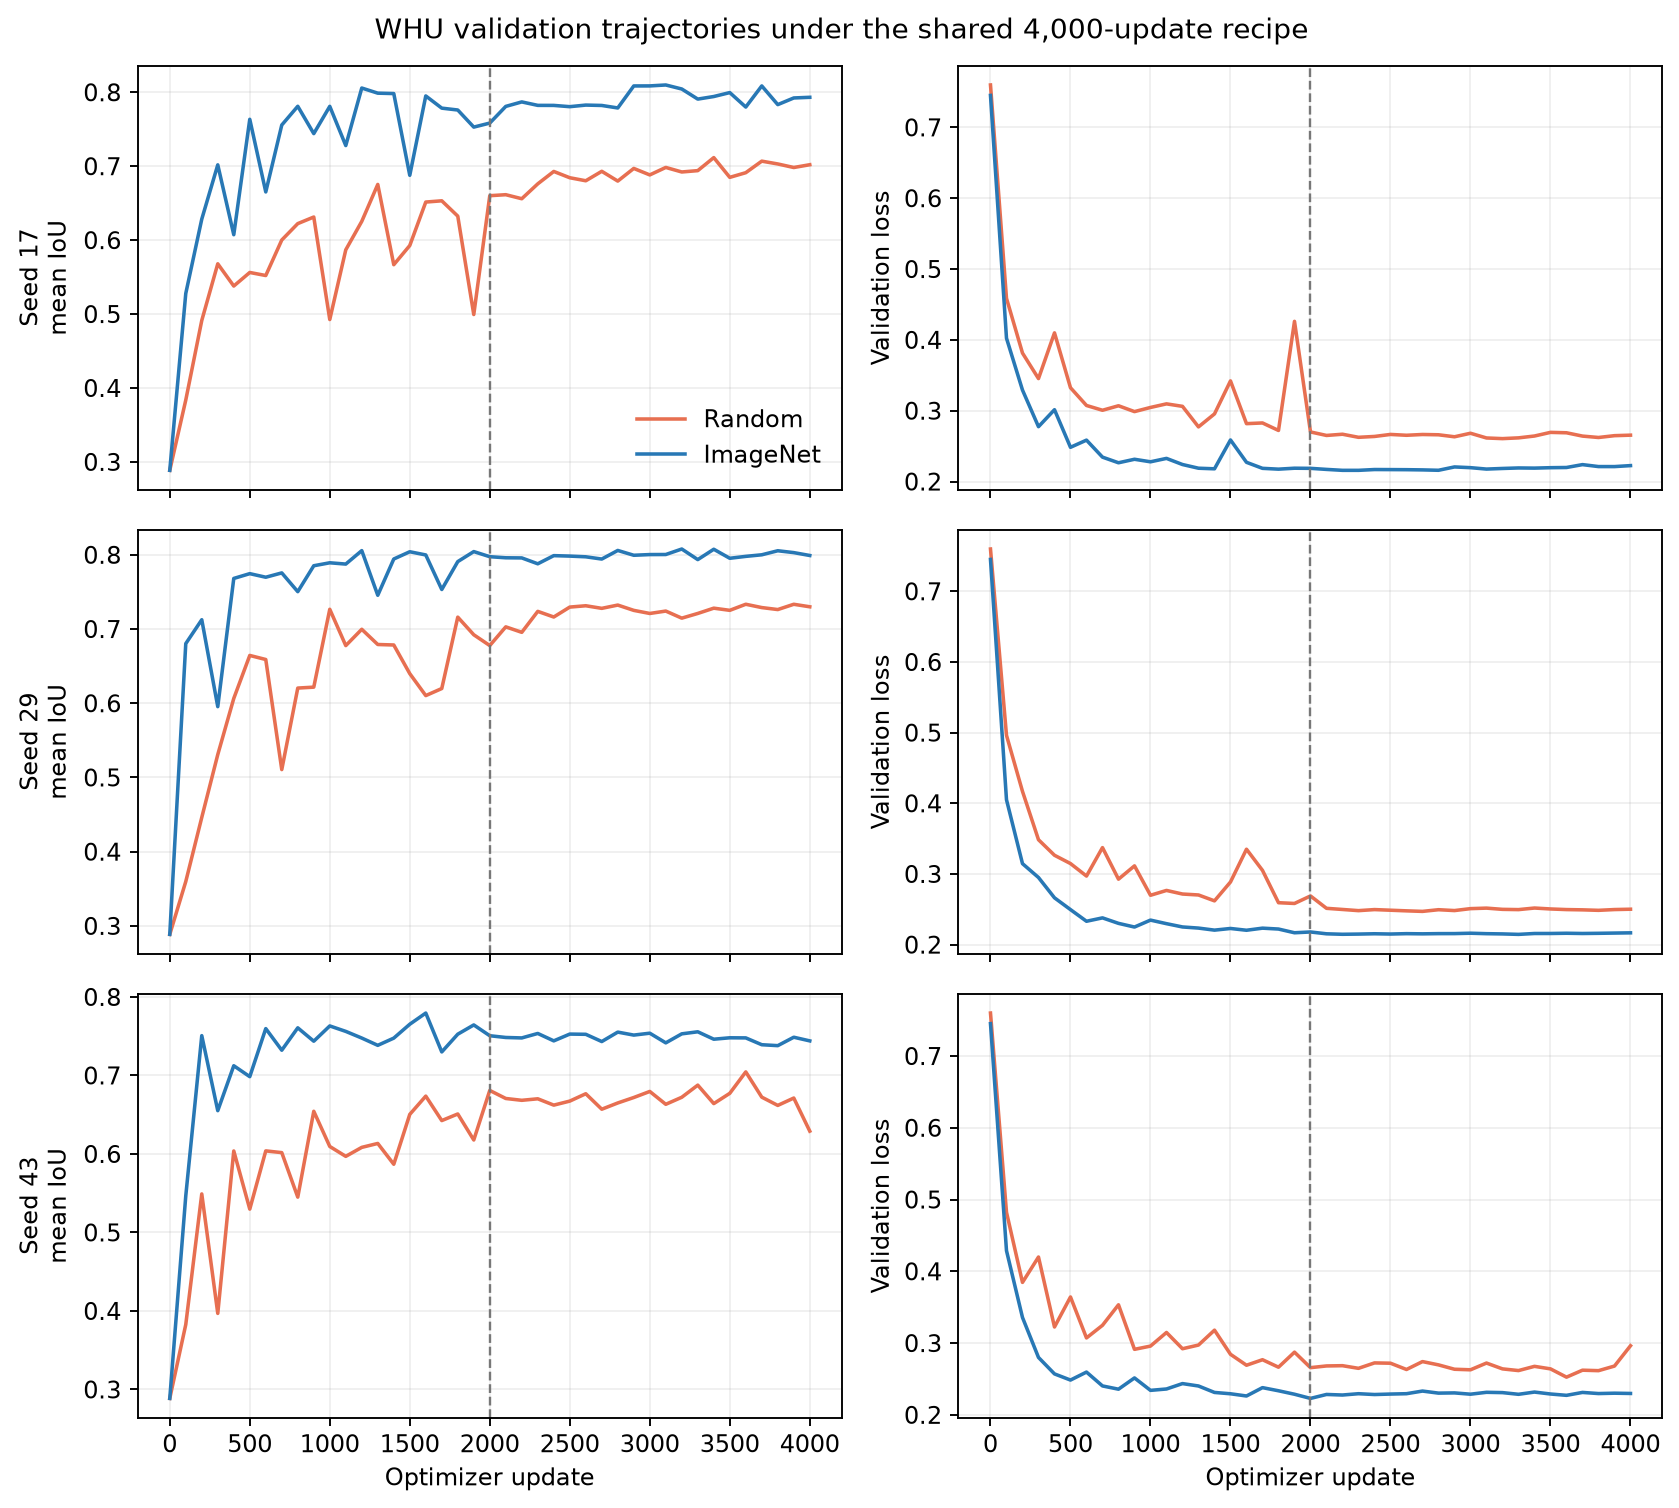

In [4]:
display(N100_EFFECTS.round(4))
display(Image(filename=ROOT / "reports/figures/07_whu_pilot_learning_curves.png"))

The three n=100 effects are +0.0983, +0.0744 and +0.0750. Their mean of 0.0826 and sample standard deviation of 0.0136 describe variation over these three image selections while all other random seeds and the validation data are fixed.

## 4. Data-efficiency results

The next figure shows individual seed trajectories as faint lines and their three-selection means as heavier lines. The adjacent table reports the corresponding mean and sample standard deviation (`ddof=1`). Individual values remain essential: three selections are too few for a confidence interval, and the standard deviation measures only training-image selection under fixed remaining seeds. Selected maxima and step-4,000 endpoints answer different questions because a fixed update budget need not yield equal convergence.

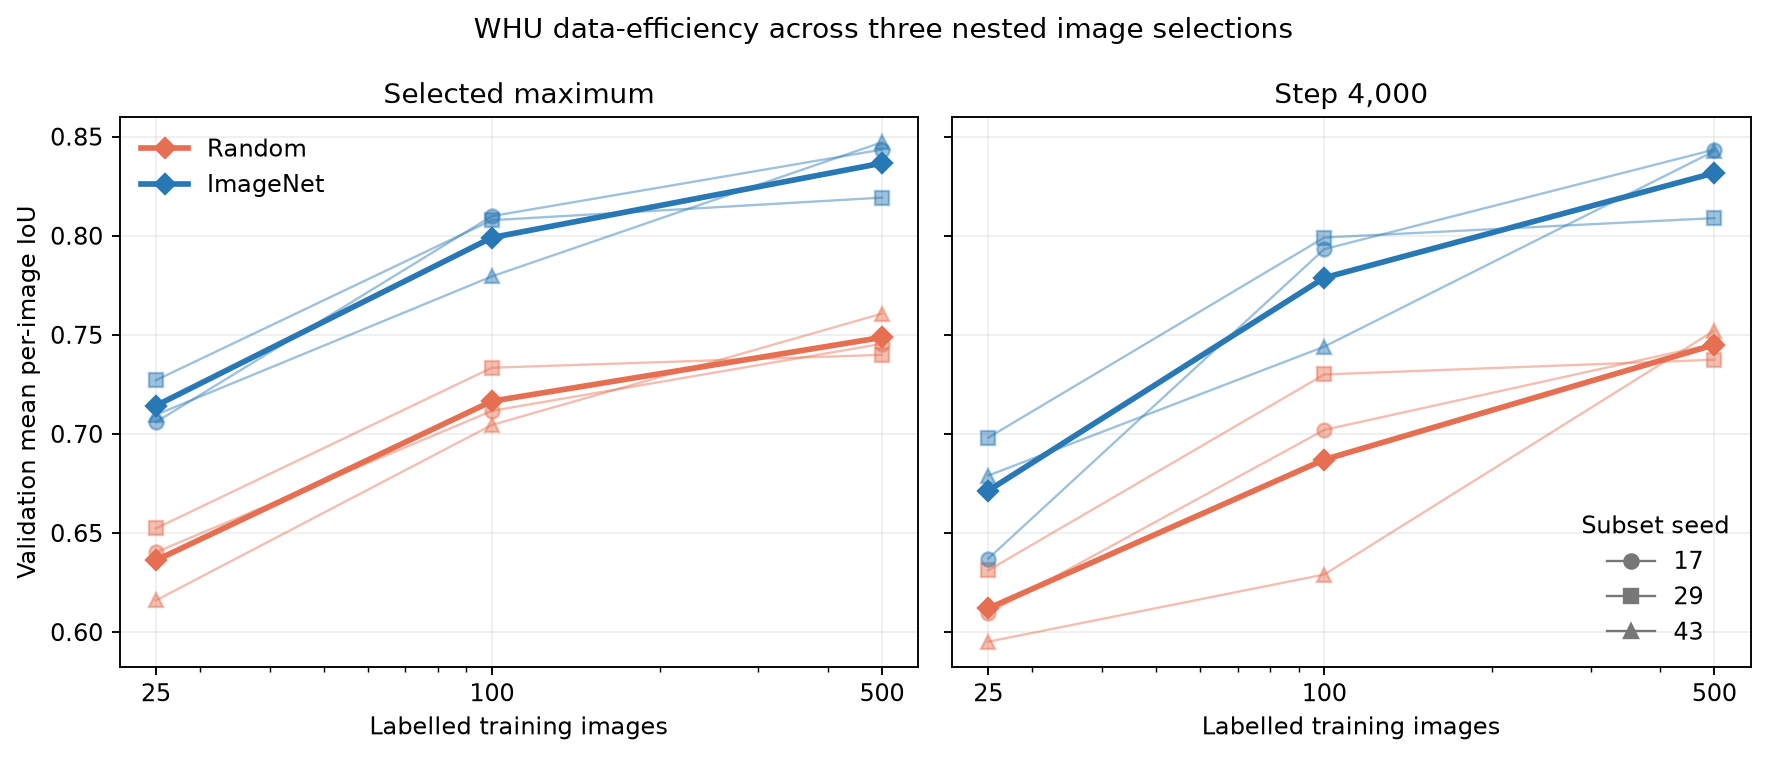

,Training images,Initialization,Best IoU mean,Best IoU sample SD,Final IoU mean,Final IoU sample SD
0,25,imagenet,0.7142,0.0113,0.6714,0.0312
1,25,random,0.6362,0.0185,0.6120,0.0181
2,100,imagenet,0.7991,0.0170,0.7788,0.0302
3,100,random,0.7165,0.0150,0.6870,0.0521
4,500,imagenet,0.8366,0.0152,0.8317,0.0197
5,500,random,0.7487,0.0108,0.7450,0.0073


In [5]:
display(Image(filename=ROOT / "reports/figures/07_whu_data_efficiency.png"))
summary_columns = {
    "training_size": "Training images", "initialization": "Initialization",
    "best_iou_mean": "Best IoU mean", "best_iou_sample_sd": "Best IoU sample SD",
    "last_iou_mean": "Final IoU mean", "last_iou_sample_sd": "Final IoU sample SD",
}
display(SUMMARY.rename(columns=summary_columns).round(4))

In [6]:
columns = {
    "subset_seed": "Seed", "training_size": "Training images",
    "initialization": "Initialization", "best_step": "Selected step",
    "best_validation_iou": "Best val IoU", "last_validation_iou": "Final val IoU",
    "last_validation_loss": "Final val loss", "selected_validation_dice": "Selected val Dice",
    "selected_validation_ap_positive": "Selected positive AP",
    "selected_training_iou": "Selected train IoU", "selected_training_loss": "Selected train loss",
    "training_validation_iou_gap": "Train–val IoU gap",
}
main_results = RESULTS[list(columns)].rename(columns=columns).copy()
main_results["Initialization"] = main_results["Initialization"].map({"random": "Random", "imagenet": "ImageNet"})
main_results.round(4)

,Seed,Training images,Initialization,Selected step,Best val IoU,Final val IoU,Final val loss,Selected val Dice,Selected positive AP,Selected train IoU,Selected train loss,Train–val IoU gap
0,17,25,ImageNet,900,0.7060,0.6371,0.2518,0.7644,0.9007,0.9097,0.1176,0.2037
1,17,25,Random,2500,0.6403,0.6096,0.3033,0.7075,0.8808,0.8911,0.1246,0.2508
2,17,100,ImageNet,3100,0.8099,0.7932,0.2225,0.8553,0.9341,0.9107,0.0985,0.1008
3,17,100,Random,3400,0.7116,0.7020,0.2655,0.7705,0.8909,0.8422,0.1427,0.1306
4,17,500,ImageNet,4000,0.8435,0.8435,0.2070,0.8856,0.9527,0.8815,0.1155,0.0380
5,17,500,Random,4000,0.7455,0.7455,0.2392,0.8015,0.9223,0.8158,0.1526,0.0704
6,29,25,ImageNet,1800,0.7271,0.6982,0.2486,0.7823,0.9158,0.8797,0.0682,0.1526
7,29,25,Random,1500,0.6523,0.6312,0.3234,0.7269,0.8576,0.8190,0.1351,0.1667
8,29,100,ImageNet,3200,0.8078,0.7991,0.2167,0.8533,0.9316,0.8962,0.0997,0.0884
9,29,100,Random,3600,0.7334,0.7300,0.2501,0.7939,0.9053,0.8383,0.1426,0.1049


Both initializations improve as the labelled set grows, but the 100-to-500 gain remains strongly selection-dependent. Best-IoU gains for Random/ImageNet are +0.0338/+0.0336 for seed 17, +0.0065/+0.0114 for seed 29 and +0.0562/+0.0677 for seed 43. Seed 43 therefore shows that the small seed-29 increment is not a stable estimate, while three selections still do not identify a precise population learning curve.

In [7]:
display(EFFECTS.round(4))
display(GAINS.round(4))

,subset_repetition,subset_seed,training_size,imagenet_minus_random_best_iou,imagenet_minus_random_last_iou
0,1,17,25,0.0657,0.0275
1,1,17,100,0.0983,0.0912
2,1,17,500,0.0980,0.0980
3,2,29,25,0.0748,0.0670
4,2,29,100,0.0744,0.0691
5,2,29,500,0.0793,0.0714
6,3,43,25,0.0937,0.0838
7,3,43,100,0.0750,0.1150
8,3,43,500,0.0865,0.0906


,subset_repetition,subset_seed,initialization,size_change,best_iou_gain,last_iou_gain
0,1,17,imagenet,25_to_100,0.1039,0.1561
1,1,17,imagenet,100_to_500,0.0336,0.0502
2,1,17,random,25_to_100,0.0713,0.0924
3,1,17,random,100_to_500,0.0338,0.0434
4,2,29,imagenet,25_to_100,0.0807,0.1010
5,2,29,imagenet,100_to_500,0.0114,0.0098
6,2,29,random,25_to_100,0.0811,0.0988
7,2,29,random,100_to_500,0.0065,0.0074
8,3,43,imagenet,25_to_100,0.0698,0.0651
9,3,43,imagenet,100_to_500,0.0677,0.0987


Pretraining helps at every size and in all three selections. The nine paired best-IoU effects range from +0.0657 to +0.0983, but their size dependence is not monotonic or identical across selections. The evidence supports a persistent advantage under the fixed recipe, not a precise functional relationship between data volume and pretraining benefit.

## 5. Complete training trajectories

The vertical line marks the fixed learning-rate reduction after update 2,000. Full curves are shown separately for each selection so oscillation and late behavior are not hidden by averaging.

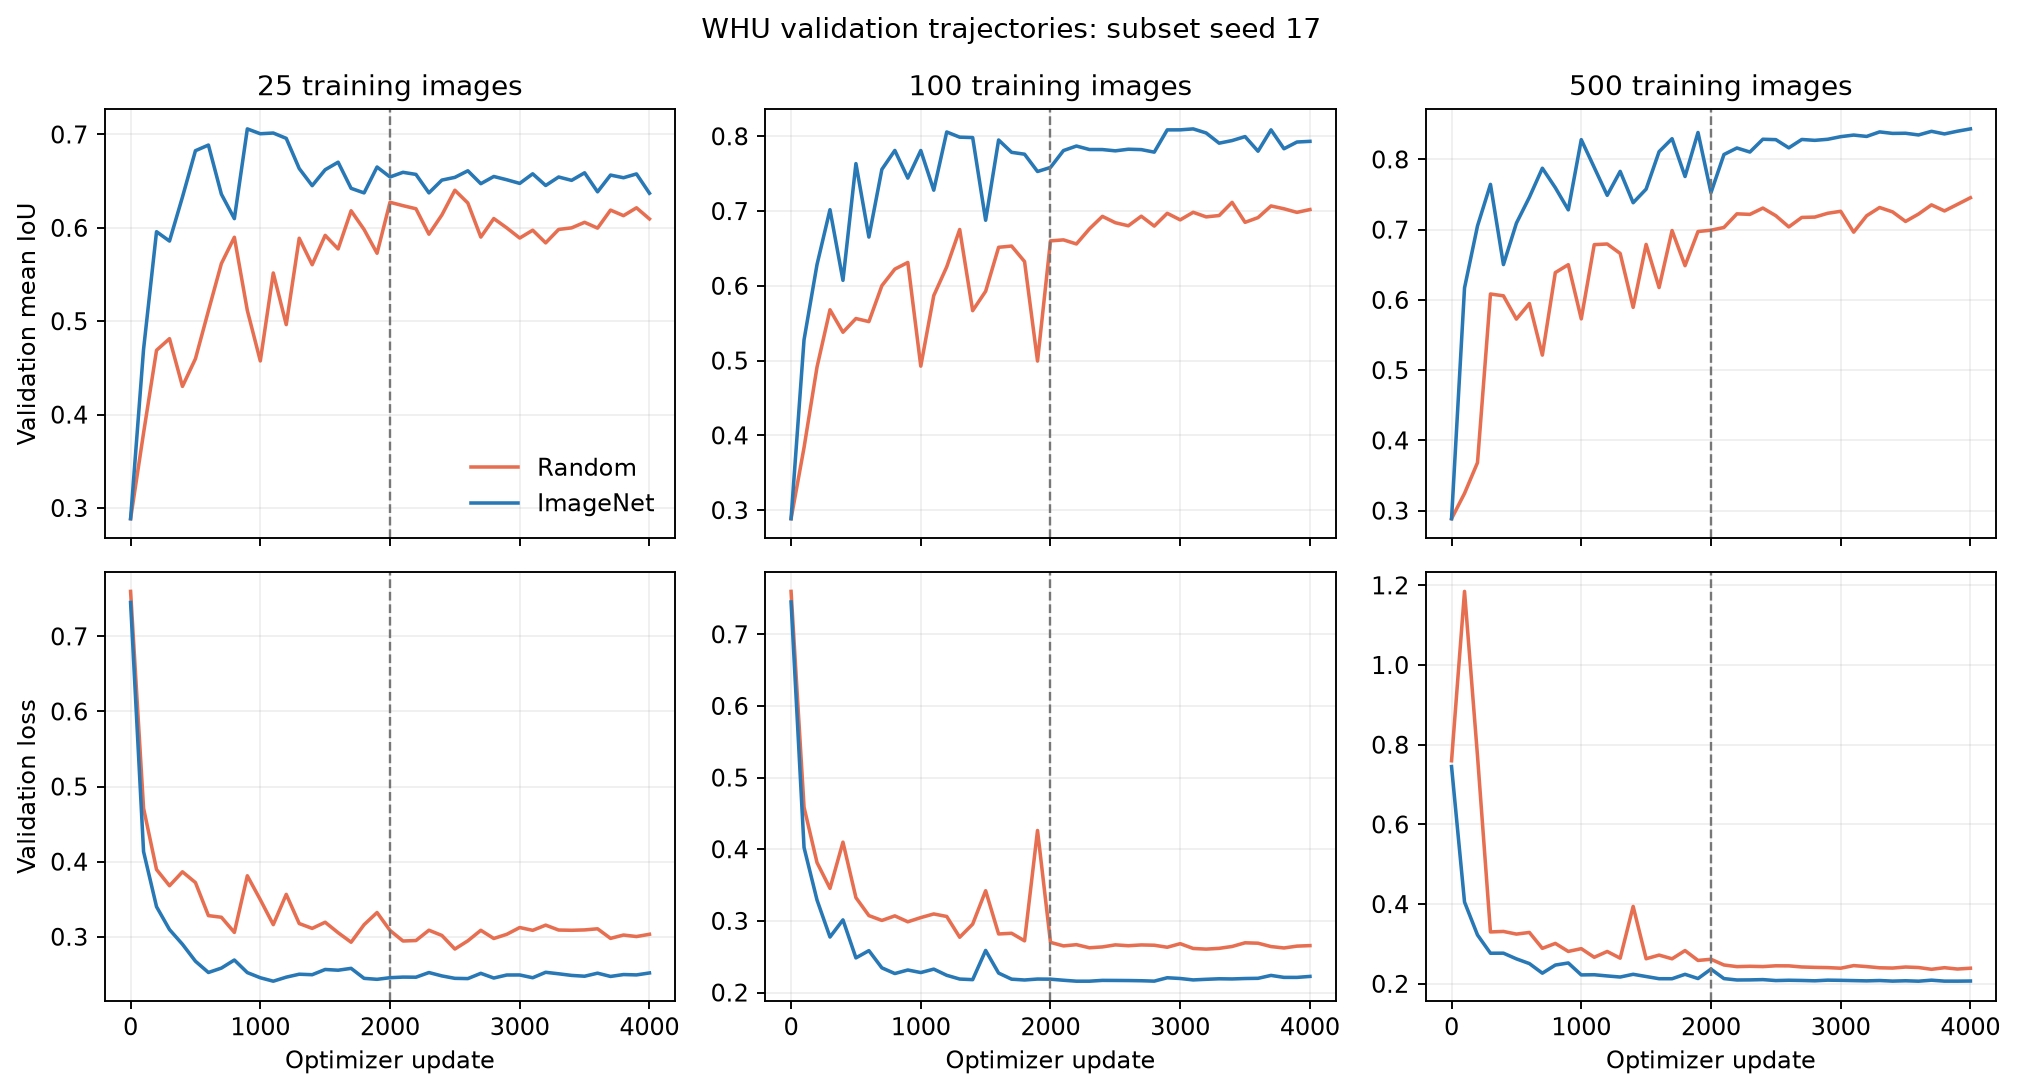

In [8]:
display(Image(filename=ROOT / "reports/figures/07_whu_learning_curves_seed17.png"))

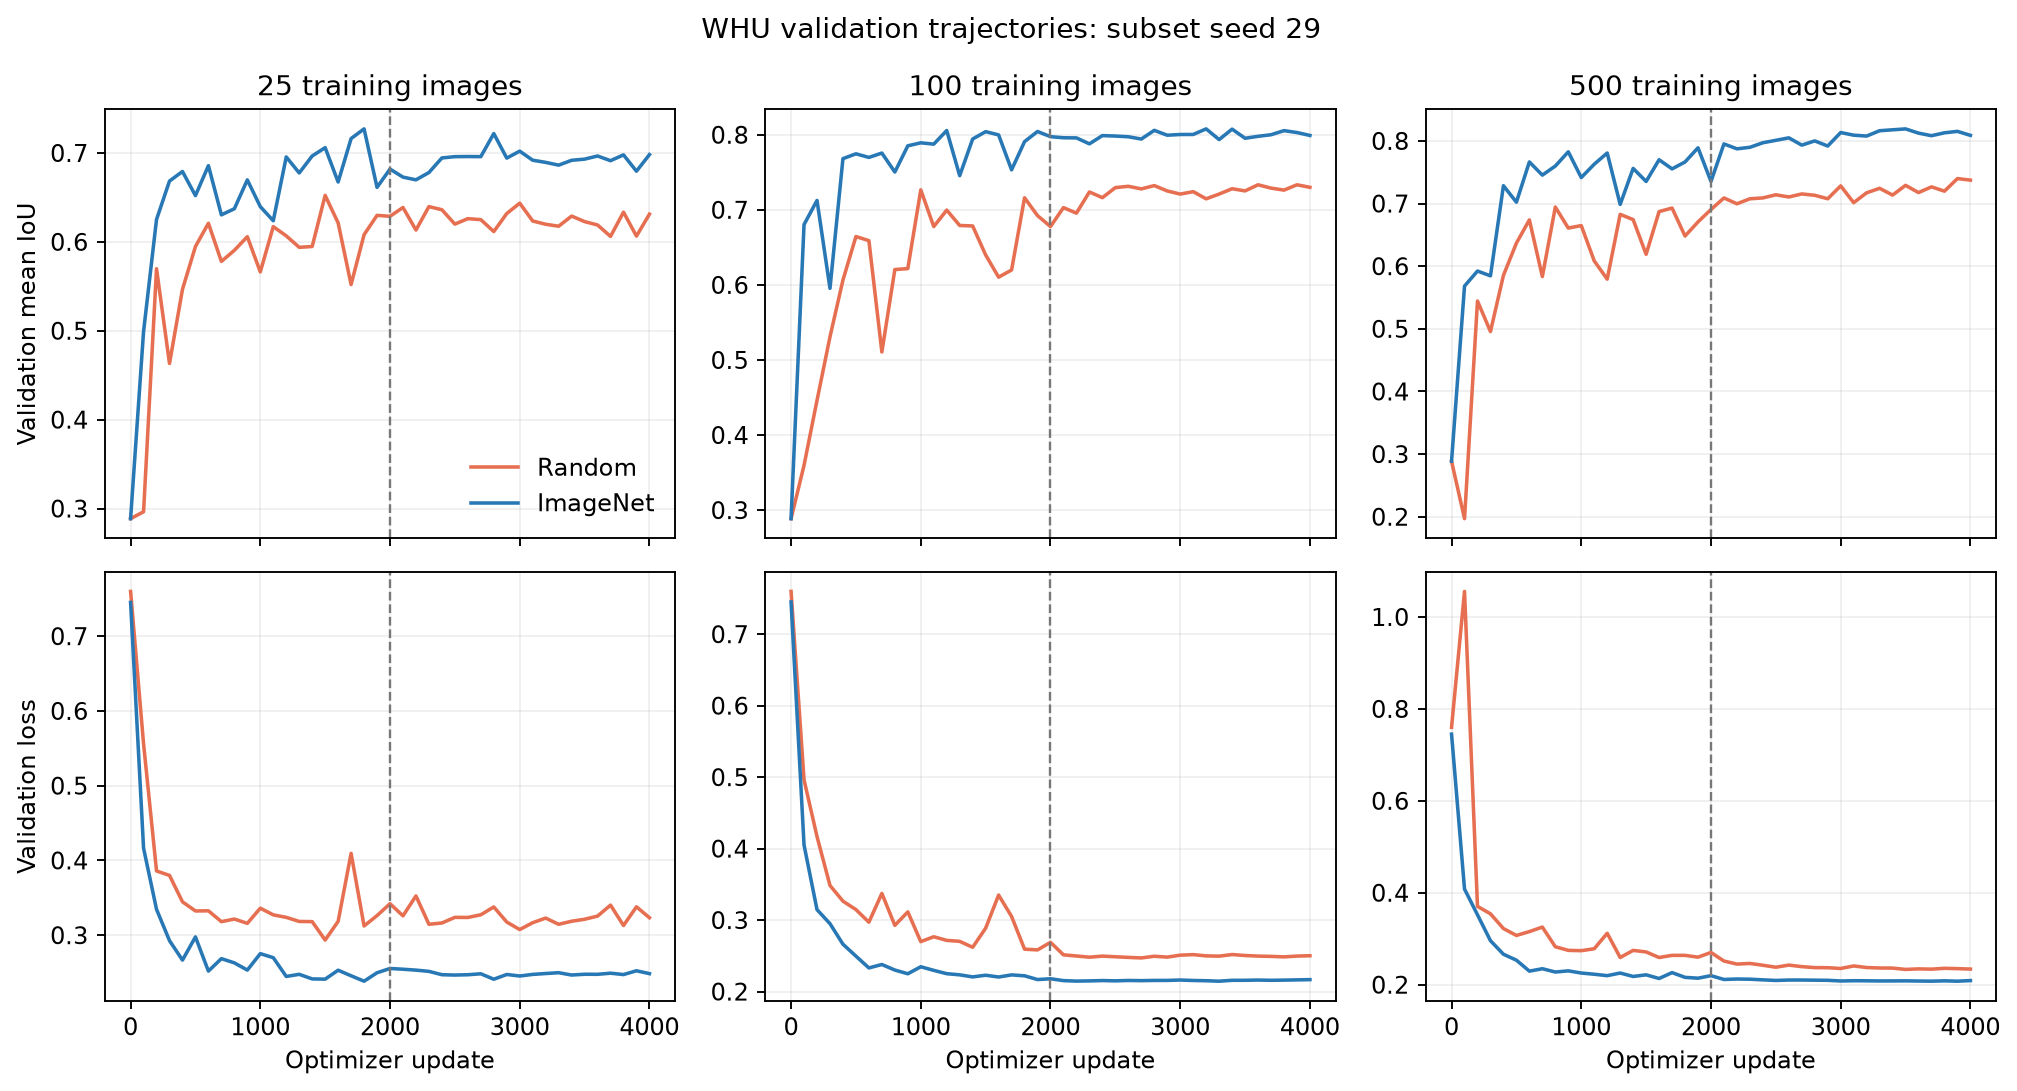

In [9]:
display(Image(filename=ROOT / "reports/figures/07_whu_learning_curves_seed29.png"))

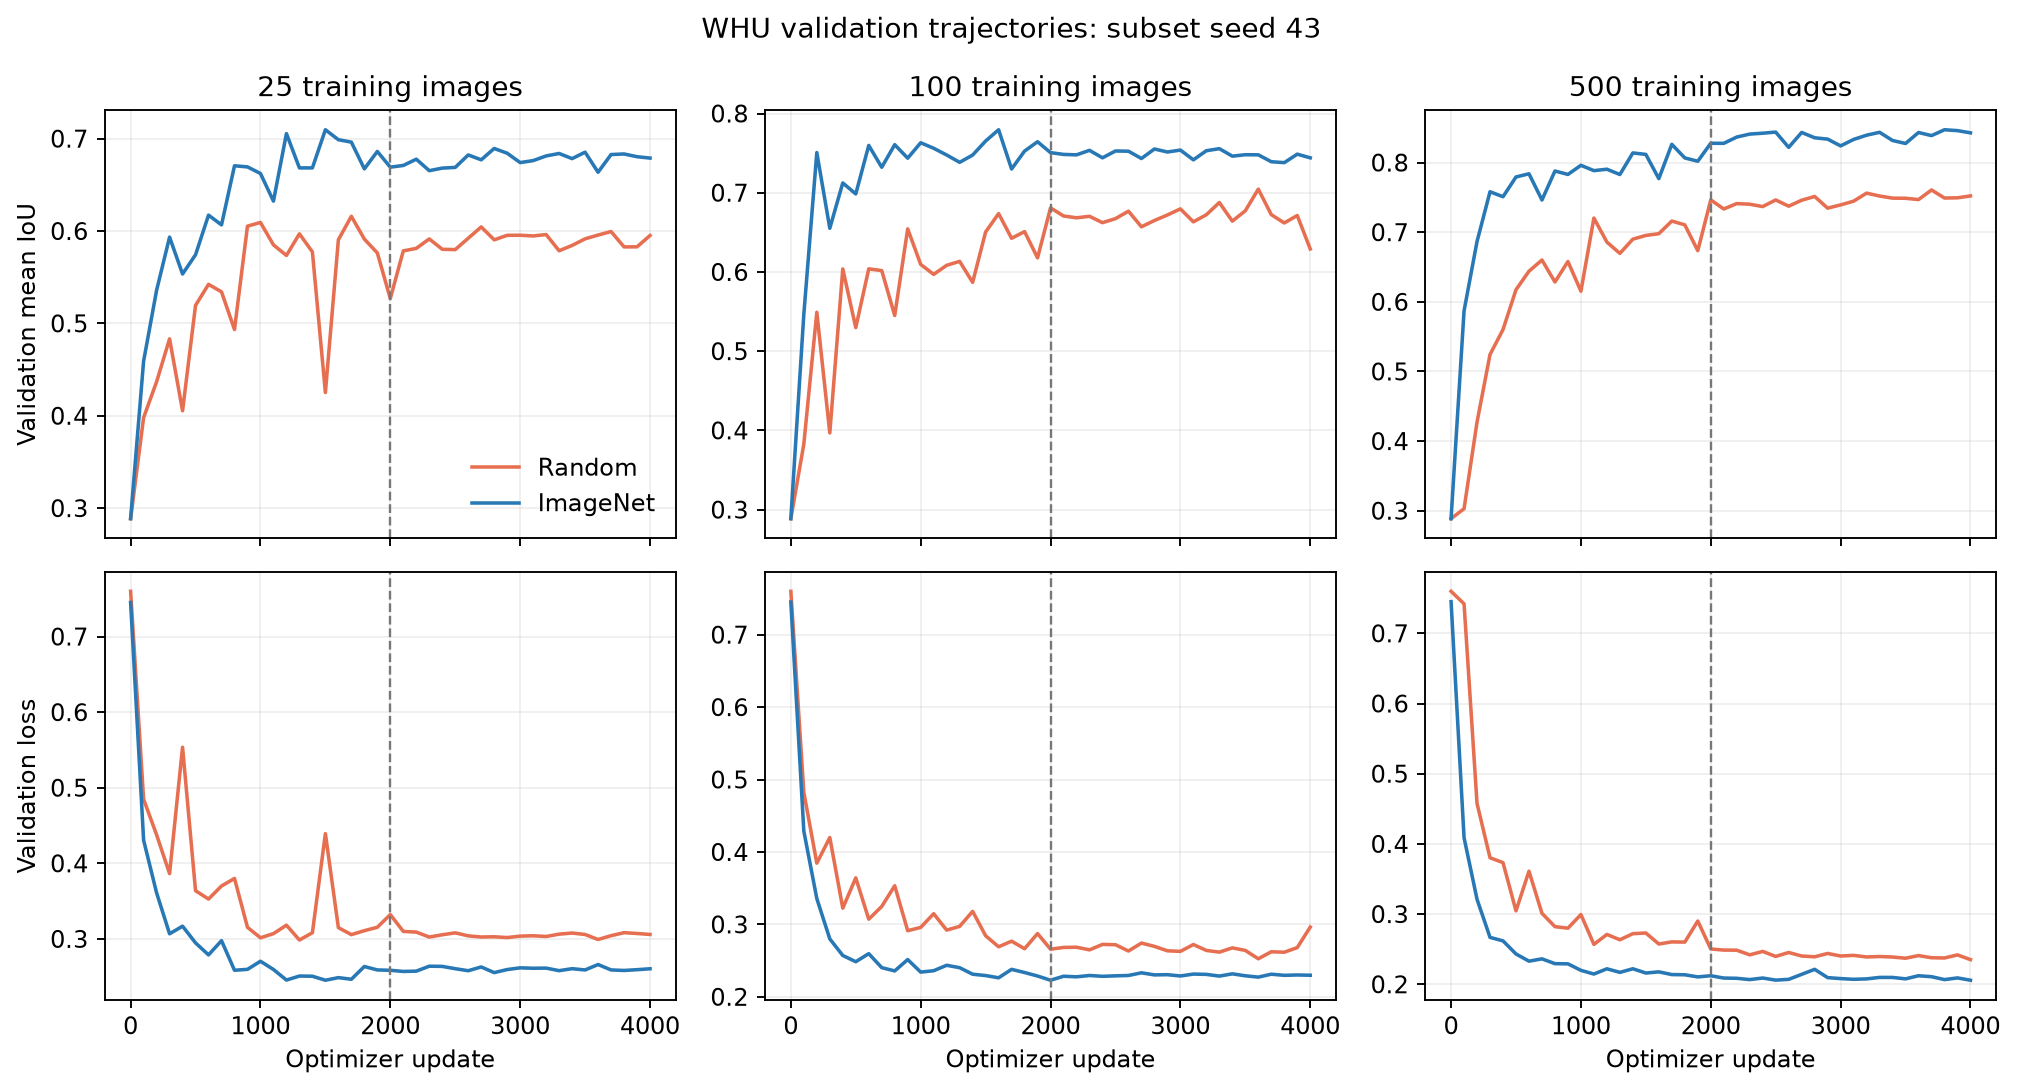

In [10]:
display(Image(filename=ROOT / "reports/figures/07_whu_learning_curves_seed43.png"))

At n=25, selected steps range from 900 to 2,500 and every endpoint is lower than its selected maximum by 0.021–0.069 IoU. The selected-checkpoint train–validation gaps are also largest at this size (0.153–0.253). Together with falling training loss and unstable or declining validation IoU, this is consistent with early overfitting in all three selections.

At n=500, all six late-window IoU slopes are positive (+0.0039 to +0.0152 per 1,000 updates). Best steps range from 3,500 to 4,000. Thus the larger-data models are still improving near the budget boundary; the common 4,000-update budget does not demonstrate equal convergence or optimal achievable performance.

In [11]:
late_columns = {
    "subset_seed": "Seed", "training_size": "Training images",
    "initialization": "Initialization", "best_step": "Selected step",
    "last_minus_best_validation_iou": "Final − best IoU",
    "iou_trend_per_1000": "Late IoU trend / 1,000",
    "iou_residual_sd": "Late IoU residual SD",
}
late = RESULTS[list(late_columns)].rename(columns=late_columns).copy()
late["Initialization"] = late["Initialization"].map({"random": "Random", "imagenet": "ImageNet"})
late.round(4)

,Seed,Training images,Initialization,Selected step,Final − best IoU,"Late IoU trend / 1,000",Late IoU residual SD
0,17,25,ImageNet,900,-0.0689,-0.0021,0.0071
1,17,25,Random,2500,-0.0307,-0.0041,0.0140
2,17,100,ImageNet,3100,-0.0167,0.0072,0.0101
3,17,100,Random,3400,-0.0096,0.0179,0.0089
4,17,500,ImageNet,4000,0.0000,0.0152,0.0046
5,17,500,Random,4000,0.0000,0.0101,0.0099
6,29,25,ImageNet,1800,-0.0289,0.0049,0.0106
7,29,25,Random,1500,-0.0212,-0.0059,0.0099
8,29,100,ImageNet,3200,-0.0087,0.0037,0.0044
9,29,100,Random,3600,-0.0034,0.0095,0.0079


The residual standard deviation summarizes scatter around the fitted late trend. It is descriptive, not a prediction interval. It separates a smooth upward tendency from noisy validation movement without changing checkpoint selection.

## 6. Positive and empty-reference behavior

The primary metric combines two distinct abilities: segmenting buildings when present and avoiding false building pixels when the reference is empty. The selected checkpoints are therefore decomposed using the same reference-defined groups as the original pilot.

In [12]:
group_columns = {
    "subset_seed": "Seed", "training_size": "Training images",
    "initialization": "Initialization", "positive_mean_iou": "Positive IoU",
    "positive_mean_dice": "Positive Dice",
    "selected_validation_ap_positive": "Positive AP",
    "empty_mean_predicted_building_fraction": "Predicted fraction on empty",
    "empty_fraction_with_any_prediction": "Empty images with any prediction",
}
groups = RESULTS[list(group_columns)].rename(columns=group_columns).copy()
groups["Initialization"] = groups["Initialization"].map({"random": "Random", "imagenet": "ImageNet"})
groups.round(4)

,Seed,Training images,Initialization,Positive IoU,Positive Dice,Positive AP,Predicted fraction on empty,Empty images with any prediction
0,17,25,ImageNet,0.7549,0.8370,0.9007,0.0042,0.4147
1,17,25,Random,0.7074,0.8019,0.8808,0.0241,0.5251
2,17,100,ImageNet,0.8115,0.8753,0.9341,0.0005,0.1940
3,17,100,Random,0.7208,0.8035,0.8909,0.0153,0.3110
4,17,500,ImageNet,0.8315,0.8907,0.9527,0.0003,0.1271
5,17,500,Random,0.7630,0.8418,0.9223,0.0066,0.2977
6,29,25,ImageNet,0.7779,0.8555,0.9158,0.0099,0.3980
7,29,25,Random,0.6633,0.7680,0.8576,0.0162,0.3746
8,29,100,ImageNet,0.8167,0.8806,0.9316,0.0018,0.2140
9,29,100,Random,0.7446,0.8297,0.9053,0.0075,0.2943


The n=25-to-n=500 improvement comes from both components. Positive-reference IoU rises for every seed/initialization combination, and mean predicted building fraction on empty references falls in all six matched comparisons. For seed 43, positive IoU rises from 0.650 to 0.772 for Random and from 0.757 to 0.833 for ImageNet, while predicted empty-image building fraction falls from 2.17% to 0.97% and from 0.27% to 0.08%. More labelled images therefore improve building overlap and false-positive control rather than only exploiting the empty-mask convention.

## 7. Update budget, data reuse and runtime

All runs use 4,000 optimizer updates, but this does not equalize exposure to the labelled set. Because the final one-image batch is retained at n=25, those runs process 14,287 examples rather than 16,000. The same images are reused about 571 times at n=25, 160 times at n=100 and 32 times at n=500.

In [13]:
effort_columns = {
    "subset_seed": "Seed", "training_size": "Training images",
    "initialization": "Initialization", "examples_processed": "Examples processed",
    "equivalent_data_passages": "Equivalent data passages",
    "incomplete_batches_retained": "Incomplete batch retained",
    "training_seconds": "Optimization minutes", "total_seconds": "Total minutes",
}
effort = RESULTS[list(effort_columns)].rename(columns=effort_columns).copy()
effort["Optimization minutes"] /= 60
effort["Total minutes"] /= 60
effort.round(2)

,Seed,Training images,Initialization,Examples processed,Equivalent data passages,Incomplete batch retained,Optimization minutes,Total minutes
0,17,25,imagenet,14287,571.48,True,18.98,35.75
1,17,25,random,14287,571.48,True,18.93,35.55
2,17,100,imagenet,16000,160.00,False,21.19,38.14
3,17,100,random,16000,160.00,False,21.08,38.09
4,17,500,imagenet,16000,32.00,False,21.14,38.66
5,17,500,random,16000,32.00,False,21.12,38.42
6,29,25,imagenet,14287,571.48,True,19.18,36.21
7,29,25,random,14287,571.48,True,19.08,35.97
8,29,100,imagenet,16000,160.00,False,21.26,38.23
9,29,100,random,16000,160.00,False,21.06,37.86


The four Seed-43 n=25 and n=500 runs required **82.1 optimization minutes** and **151.5 total minutes** on MPS, including scheduled validation and selected-checkpoint evaluation. Across all three selections, the twelve n=25/n=500 runs required 246.1 optimization minutes and 454.6 total minutes. Runtime differences do not alter the fixed update contract.

## 8. Context from RID and qualitative WHU cases

The closest cross-dataset comparison uses uniform-random n=100 selections with the same 4,000-update schedule. ImageNet has a positive paired effect for all three selections on both RID and WHU. Across both datasets, more labelled images improve the validation learning curves, the smallest subsets show the clearest train–validation separation, and n=500 Random models retain positive late progress. These recurring observations concern direction under each dataset's own validation contract.

Several findings remain dataset-specific. RID's main curves use spatial-maximin selection, georeferenced image footprints and roof-segment targets; WHU uses uniform selection because its prepared tiles lack reconstructable coordinates, evaluates building footprints and contains many empty masks. Absolute IoUs therefore do not isolate a dataset effect, and the WHU empty-reference diagnostics have no direct RID counterpart.

,dataset,subset_seed,random_best_iou,imagenet_best_iou,imagenet_minus_random_best_iou
0,RID,17,0.8245,0.8637,0.0392
1,RID,29,0.8185,0.8668,0.0482
2,RID,43,0.8298,0.8670,0.0372
3,WHU,17,0.7116,0.8099,0.0983
4,WHU,29,0.7334,0.8078,0.0744
5,WHU,43,0.7045,0.7795,0.0750


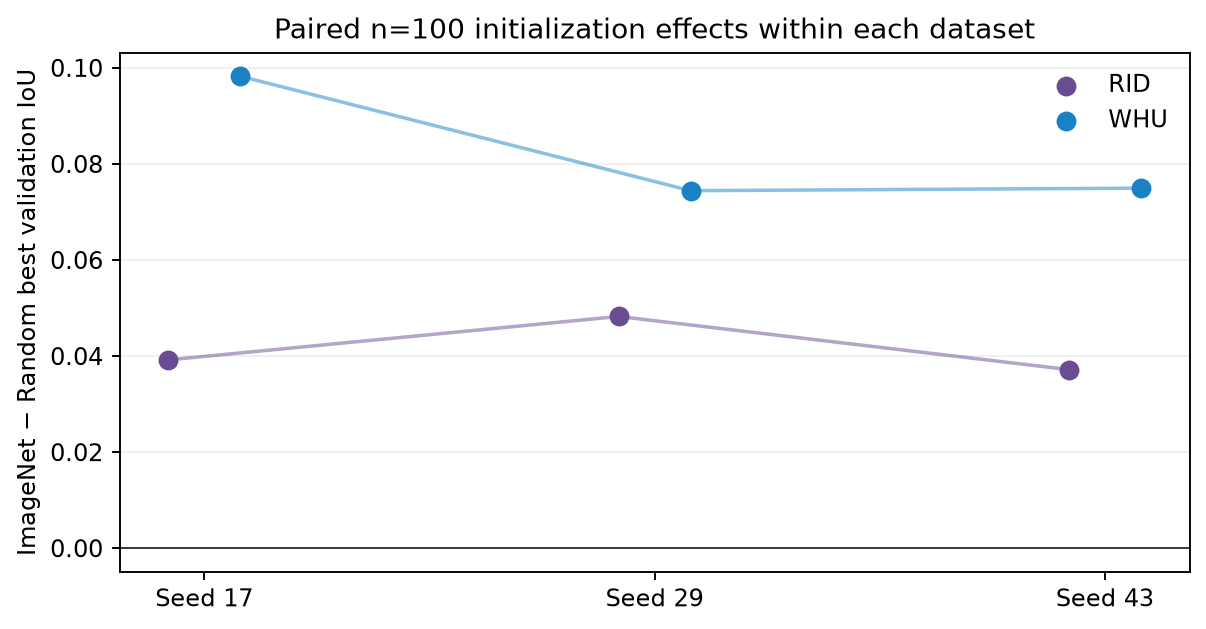

In [14]:
display(CROSS_DATASET.round(4))
display(Image(filename=ROOT / "reports/figures/07_whu_rid_initialization_effects.png"))

The qualitative examples use the seed-17 n=100 pair and symmetric criteria based on both models' validation metrics. Green denotes true positives, orange false positives and blue false negatives. Metric-selected examples illustrate successes and failures; they do not estimate their prevalence.

In [15]:
EXAMPLES

,selection,id,reference_positive,paired_mean_iou,paired_mean_predicted_fraction
0,positive failure,val/val_0,True,0.000000,0.000046
1,positive success,val/val_124,True,0.983227,0.383345
2,empty success,val/val_10,False,1.000000,0.000000
3,empty failure,val/val_158,False,0.500000,0.178183


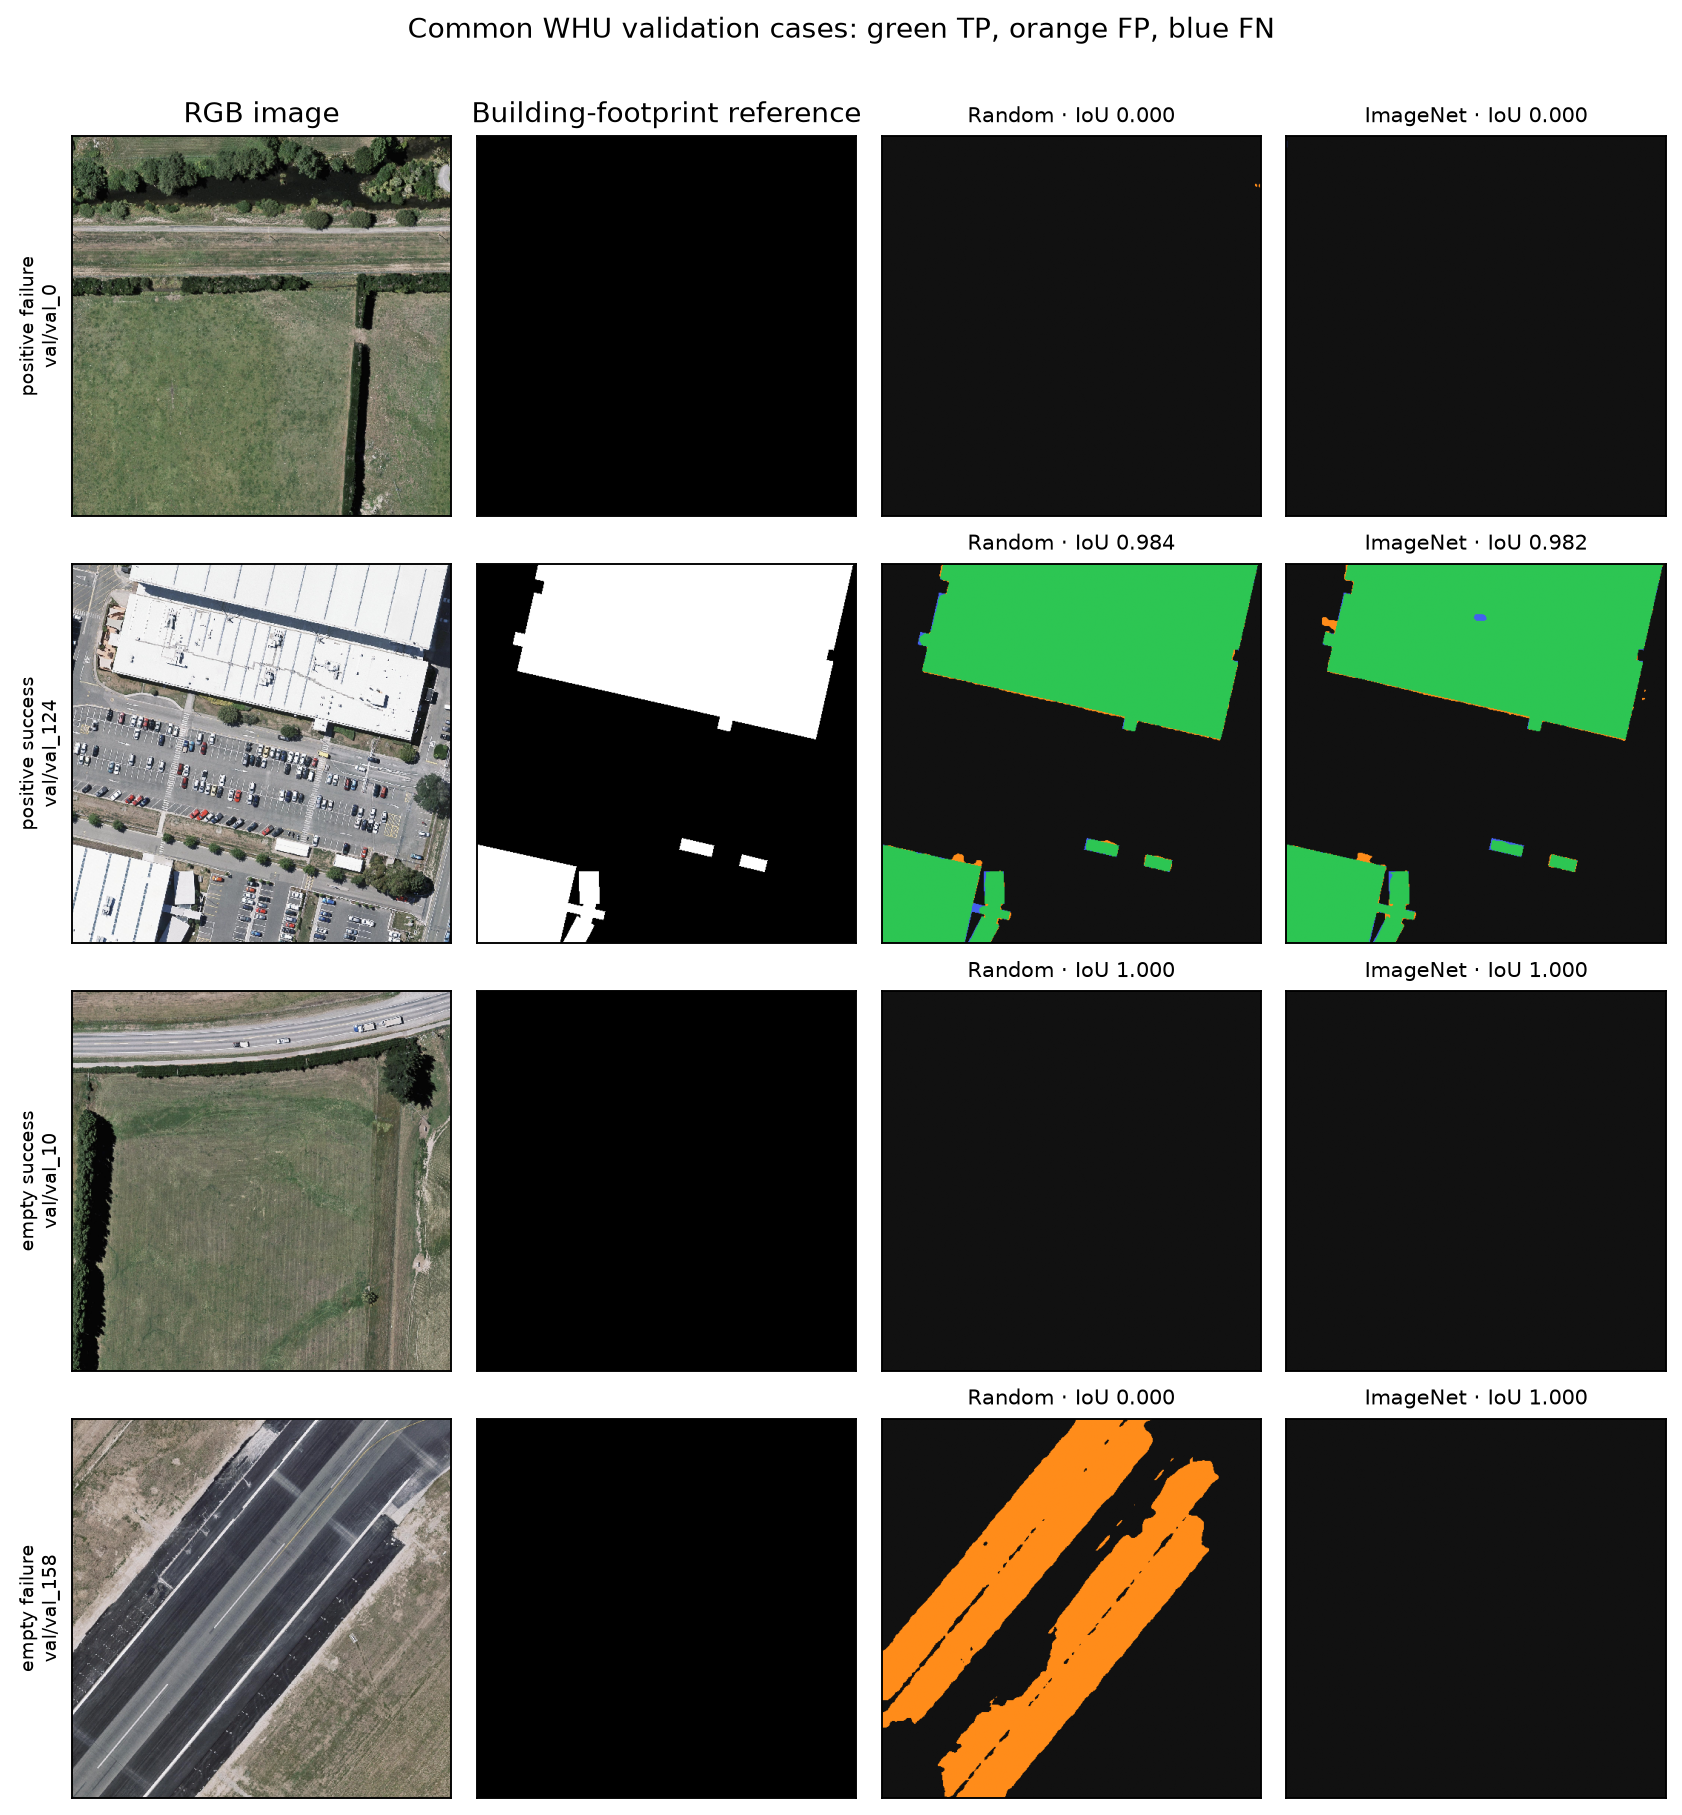

In [16]:
display(Image(filename=ROOT / "reports/figures/07_whu_pilot_validation_examples.png"))

The examples show an accurately segmented large building, a completely missed small target and an empty road scene where Random predicts extensive false buildings while ImageNet remains empty. They illustrate mechanisms behind the aggregate metrics but are not a separately sampled benchmark.

## 9. Sensitivity to an 8,000-update budget

All six n=500 budget runs start from fresh random parameters or the original ImageNet encoder weights with a fresh decoder. The sole experimental change is extending the second, constant-`1e-4` phase from update 4,000 to 8,000. Each run retains its best checkpoint through update 4,000 as well as the best checkpoint over the full trajectory. This supports a primary within-run comparison that is unaffected by separate restarts.

The endpoint at update 8,000 and the mean of the final five evaluations are the central measures. A selected maximum is complementary because a longer run necessarily offers more selection opportunities. The equal-length trend windows 2,100–4,000 and 6,100–8,000 describe direction and residual scatter; adjacent evaluations are not independent repetitions.

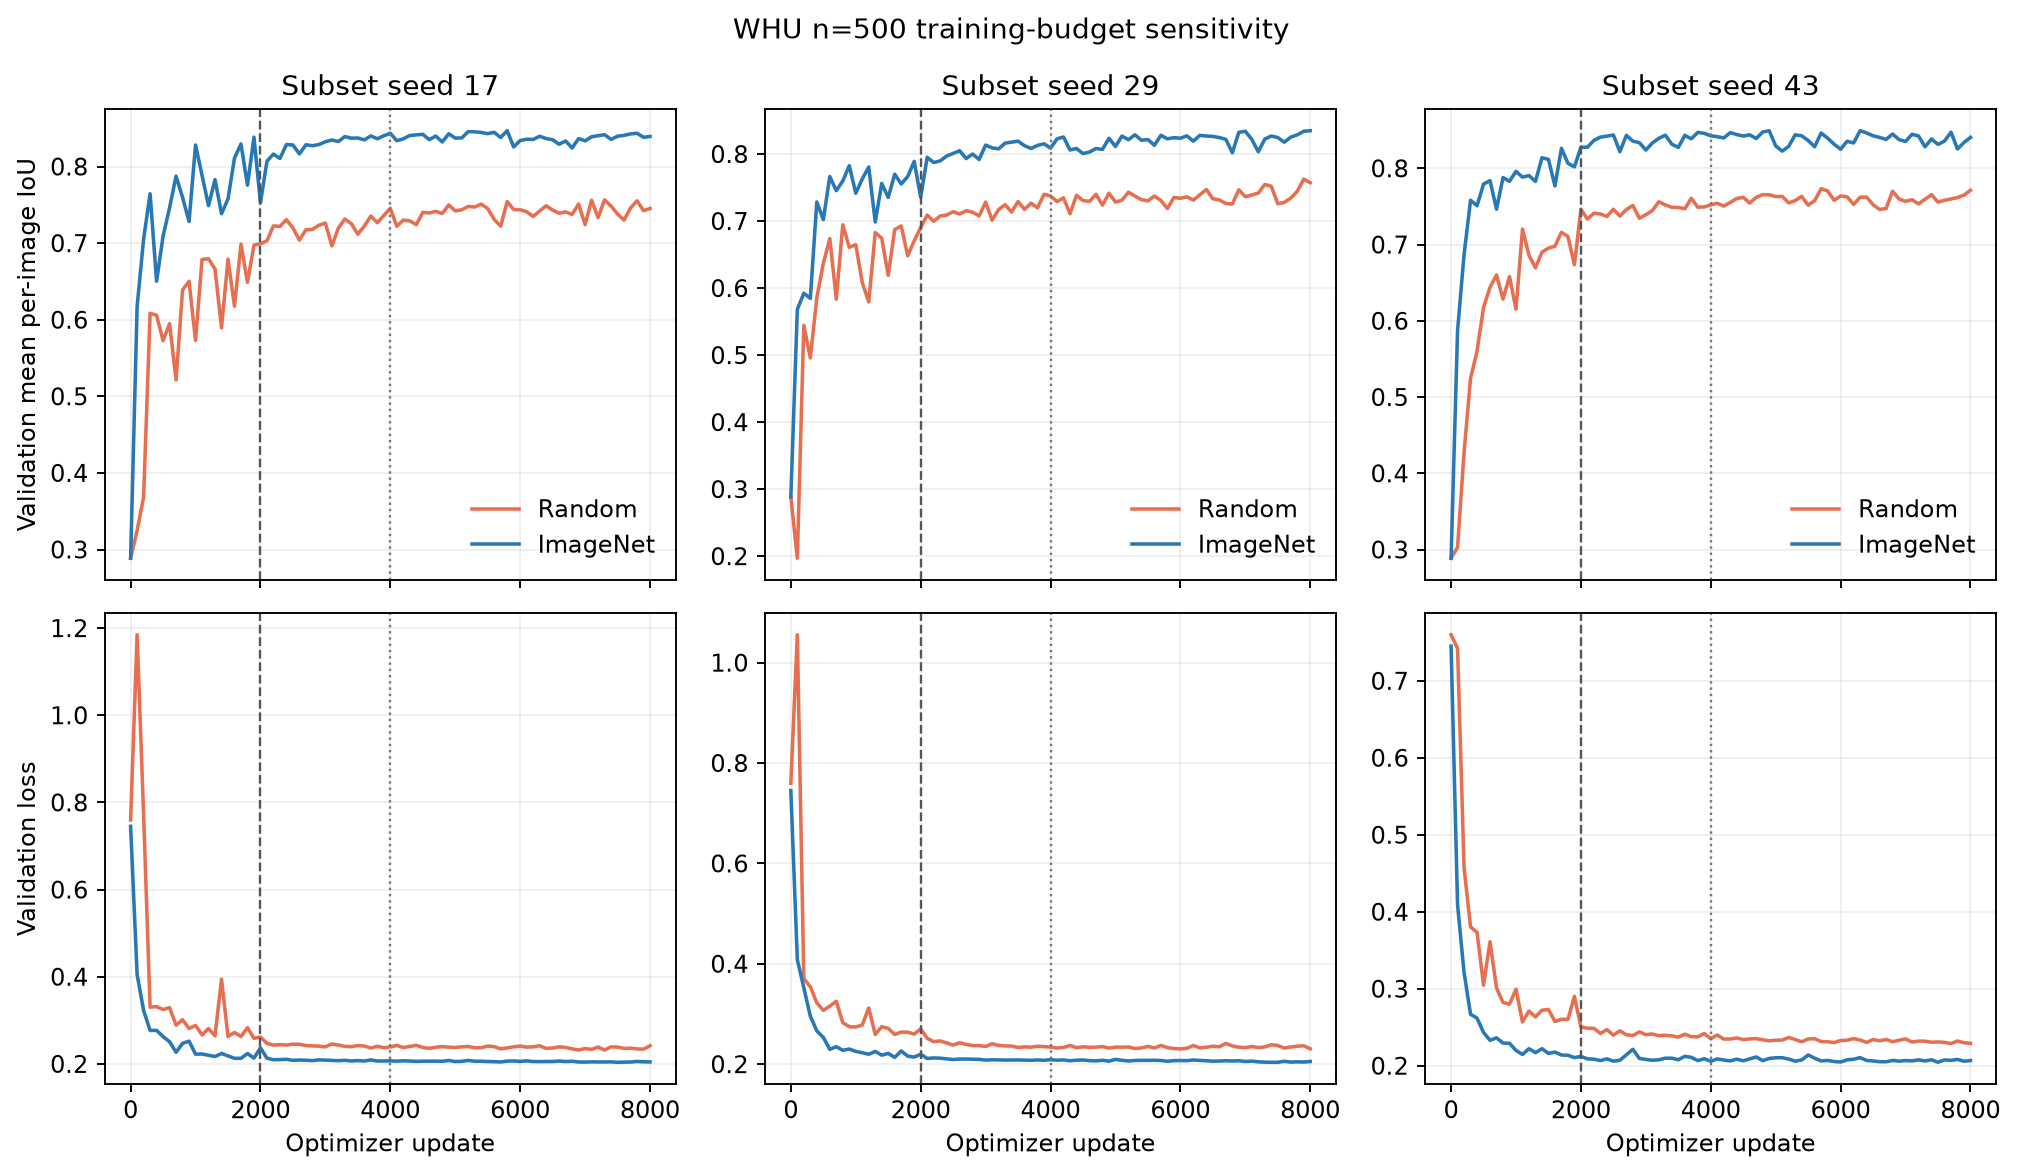

In [17]:
display(Image(filename=ROOT / "reports/figures/07_whu_training_budget_histories.png"))


**Figure 8.** Complete validation IoU and loss trajectories for the three fresh n=500 pairs. Dashed lines mark the learning-rate change at update 2,000; dotted lines mark the preserved 4,000-update prefix. The curves show substantial selection-specific variation after update 4,000 rather than a uniform benefit from additional updates.

In [18]:
endpoint_columns = {
    "subset_seed": "Seed", "initialization": "Initialization",
    "iou_step_4000": "IoU at 4,000", "iou_step_8000": "IoU at 8,000",
    "iou_change_8000_minus_4000": "Endpoint change",
    "mean_iou_last5_to_4000": "Last-five mean to 4,000",
    "mean_iou_last5_to_8000": "Last-five mean to 8,000",
    "mean_last5_change_8000_minus_4000": "Last-five change",
}
BUDGET_RESULTS[list(endpoint_columns)].rename(columns=endpoint_columns).round(4)


,Seed,Initialization,"IoU at 4,000","IoU at 8,000",Endpoint change,"Last-five mean to 4,000","Last-five mean to 8,000",Last-five change
0,17,imagenet,0.8435,0.8392,-0.0042,0.8390,0.8409,0.0019
1,17,random,0.7455,0.7453,-0.0002,0.7332,0.7438,0.0106
2,29,imagenet,0.8089,0.8349,0.0260,0.8116,0.8281,0.0165
3,29,random,0.7375,0.7573,0.0199,0.7283,0.7453,0.0170
4,43,imagenet,0.8427,0.8406,-0.0021,0.8436,0.8366,-0.0069
5,43,random,0.7521,0.7712,0.0191,0.7516,0.7632,0.0115


Random's endpoint changes are −0.0002, +0.0199 and +0.0191 for seeds 17, 29 and 43. Its final-five means improve more consistently, by +0.0106, +0.0170 and +0.0115. ImageNet endpoint changes are −0.0042, +0.0260 and −0.0021; final-five changes are +0.0019, +0.0165 and −0.0069. Thus both initializations benefit for Seed 29, but only Random shows a consistent stable-window gain across all three image selections.

In [19]:
selected_columns = {
    "subset_seed": "Seed", "initialization": "Initialization",
    "prefix_best_step": "Best step ≤4,000",
    "prefix_best_validation_iou": "Best IoU ≤4,000",
    "full_best_step": "Best step ≤8,000",
    "full_best_validation_iou": "Best IoU ≤8,000",
    "full_selected_validation_dice": "Selected Dice",
    "full_selected_validation_ap_positive": "Selected positive-image AP",
}
BUDGET_RESULTS[list(selected_columns)].rename(columns=selected_columns).round(4)


,Seed,Initialization,"Best step ≤4,000","Best IoU ≤4,000","Best step ≤8,000","Best IoU ≤8,000",Selected Dice,Selected positive-image AP
0,17,imagenet,4000,0.8435,5800,0.8468,0.8882,0.9521
1,17,random,4000,0.7455,7300,0.7566,0.8107,0.9285
2,29,imagenet,3500,0.8192,8000,0.8349,0.8758,0.9514
3,29,random,3900,0.7399,7900,0.7626,0.8179,0.9241
4,43,imagenet,3800,0.8472,4900,0.8494,0.8917,0.9535
5,43,random,3700,0.7607,5700,0.7733,0.8272,0.9302


The full-range selected maximum increases for every run, by construction never losing the prefix maximum. Selected steps move beyond 4,000 in all six runs and range from 4,900 to 8,000. This supports continued opportunity for checkpoint selection, but it is weaker evidence than endpoint and stable-window changes because the original maximum remains eligible.

In [20]:
trend_columns = {
    "subset_seed": "Seed", "initialization": "Initialization",
    "early_iou_trend_per_1000": "IoU trend 2,100–4,000",
    "late_iou_trend_per_1000": "IoU trend 6,100–8,000",
    "late_iou_residual_sd": "Late residual SD",
    "prefix_empty_mean_predicted_building_fraction": "Empty predicted fraction ≤4,000",
    "full_empty_mean_predicted_building_fraction": "Empty predicted fraction ≤8,000",
    "prefix_empty_fraction_with_any_prediction": "Empty any prediction ≤4,000",
    "full_empty_fraction_with_any_prediction": "Empty any prediction ≤8,000",
}
BUDGET_RESULTS[list(trend_columns)].rename(columns=trend_columns).round(4)


,Seed,Initialization,"IoU trend 2,100–4,000","IoU trend 6,100–8,000",Late residual SD,"Empty predicted fraction ≤4,000","Empty predicted fraction ≤8,000","Empty any prediction ≤4,000","Empty any prediction ≤8,000"
0,17,imagenet,0.0152,0.0040,0.0039,0.0003,0.0003,0.1271,0.1204
1,17,random,0.0101,0.0026,0.0082,0.0066,0.0039,0.2977,0.2943
2,29,imagenet,0.0134,0.0025,0.0084,0.0005,0.0006,0.2074,0.1706
3,29,random,0.0142,0.0079,0.0097,0.0029,0.0021,0.3378,0.2575
4,43,imagenet,0.0039,-0.0034,0.0060,0.0008,0.0006,0.1171,0.1003
5,43,random,0.0086,0.0040,0.0060,0.0097,0.0059,0.2676,0.2475


All three Random late IoU trends remain positive (+0.0026 to +0.0079 per 1,000 updates). ImageNet is positive for seeds 17 and 29 but negative for Seed 43, so 8,000 updates still do not demonstrate common convergence. Random's selected full-range checkpoints reduce mean false building area on empty references for every selection. ImageNet reduces the fraction of empty images with any prediction in every selection, while its mean false area is mixed. Empty-image control therefore contributes to some gains but does not alone explain the initialization pattern.

In [21]:
display(BUDGET_PAIRED.round(4))
display(BUDGET_SUMMARY.round(4))


,subset_seed,imagenet_minus_random_iou_step_4000,imagenet_minus_random_iou_step_8000,gap_change_8000_minus_4000,imagenet_minus_random_mean_last5_to_4000,imagenet_minus_random_mean_last5_to_8000
0,17,0.0980,0.0939,-0.0041,0.1058,0.0971
1,29,0.0714,0.0776,0.0061,0.0833,0.0828
2,43,0.0906,0.0693,-0.0212,0.0919,0.0735


,initialization,repetitions,mean_iou_change_8000_minus_4000,sample_sd_iou_change_8000_minus_4000,mean_last5_change_8000_minus_4000,sample_sd_last5_change_8000_minus_4000
0,imagenet,3,0.0065,0.0169,0.0038,0.0118
1,random,3,0.0129,0.0114,0.0131,0.0035


ImageNet's endpoint advantage remains positive at update 8,000: +0.0939, +0.0776 and +0.0693 for seeds 17, 29 and 43. The gap narrows for seeds 17 and 43 and widens for Seed 29. Across the three selections, the descriptive mean endpoint change is +0.0129 for Random and +0.0065 for ImageNet; corresponding final-five changes are +0.0131 and +0.0038. Three fixed image selections do not support a significance claim, and the experiment varies neither the remaining training randomness nor the validation region.

In [22]:
comparison = BUDGET_COMPARISON[
    ["dataset", "subset_seed", "initialization",
     "endpoint_iou_change_8000_minus_4000",
     "last5_iou_change_8000_minus_4000",
     "imagenet_minus_random_iou_step_4000",
     "imagenet_minus_random_iou_step_8000"]
]
display(comparison.round(4))
runtime = BUDGET_RESULTS[["subset_seed", "initialization", "examples_processed",
                          "equivalent_data_passages", "training_minutes", "total_minutes"]]
display(runtime.round(2))


,dataset,subset_seed,initialization,endpoint_iou_change_8000_minus_4000,last5_iou_change_8000_minus_4000,imagenet_minus_random_iou_step_4000,imagenet_minus_random_iou_step_8000
0,RID,17,imagenet,0.0004,0.0014,0.0400,0.0284
1,RID,17,random,0.0121,0.0116,0.0400,0.0284
2,RID,29,imagenet,-0.0005,0.0013,0.0322,0.0238
3,RID,29,random,0.0079,0.0096,0.0322,0.0238
4,WHU,17,imagenet,-0.0042,0.0019,0.0980,0.0939
5,WHU,17,random,-0.0002,0.0106,0.0980,0.0939
6,WHU,29,imagenet,0.0260,0.0165,0.0714,0.0776
7,WHU,29,random,0.0199,0.0170,0.0714,0.0776
8,WHU,43,imagenet,-0.0021,-0.0069,0.0906,0.0693
9,WHU,43,random,0.0191,0.0115,0.0906,0.0693


,subset_seed,initialization,examples_processed,equivalent_data_passages,training_minutes,total_minutes
0,17,imagenet,32000,64.0,98.30,163.59
1,17,random,32000,64.0,96.24,159.86
2,29,imagenet,32000,64.0,99.63,163.17
3,29,random,32000,64.0,100.89,165.39
4,43,imagenet,32000,64.0,99.84,163.17
5,43,random,32000,64.0,101.02,165.34


RID and WHU show a similar directional pattern: Random has the larger average response to the longer budget, while ImageNet remains ahead but is flatter. The comparison uses changes and paired gaps because RID has two image selections, WHU has three, and their selection strategy, resolution and target definition differ. It does not isolate a dataset effect.

Every WHU run processes 32,000 examples, equivalent to 64 passages through its 500-image subset. Per-run optimization time is 96.2–101.0 minutes and total time including validation and selected-checkpoint evaluation is 159.9–165.4 minutes on MPS. The three subset pairs were executed concurrently, so summing per-process wall times would not represent elapsed calendar time and includes device contention.

## 10. Conclusions and limitations

The main 4,000-update learning curves show that ImageNet pretraining improves validation IoU across all three WHU training selections at 25, 100 and 500 images. The smallest sets retain the clearest train–validation separation, while additional data improves positive-building segmentation and false-positive control on empty images.

The fresh 8,000-update block shows that training budget matters most consistently for Random initialization: all three final-five means improve, and all three late trends remain positive. ImageNet retains a substantial advantage at both budgets, but its continuation is selection-dependent and includes one declining final-five mean and late trend. The evidence therefore supports a persistent pretraining advantage under this recipe and incomplete common convergence; it does not establish an optimal horizon or an initialization-independent performance limit.

The checkpoint ranges, test populations and metrics for the held-out comparison were fixed before test inference in [the evaluation protocol](../docs/final_evaluation_protocol.md). [Notebook 8](08_final_evaluation.ipynb) reports the resulting test performance separately.